# Heterogeneous Graph Representation of Stiffened Panels

This walkthrough uses the **V3 four-node-type graph**: `plate`, `force`, `edge`, and `Disp`.
The six boundary DOFs are concatenated into `Disp`. External loading remains separate.
Only **32 real Case 1 graphs** are bundled: 24 train, 4 validation, 4 test.

The residual HGT implementation is `FHGT_YC_V2` from the research code; that network name is separate from the V3 graph representation. The small pretrained model demonstrates this released subset, not the paper's complete training experiments.

Run this notebook from the repository directory, after installing `requirements.txt`.
All files are local; no dataset download or user-specific path is required.

In [1]:
from pathlib import Path
import json
import torch
import numpy as np
from IPython.display import display
from dataset import ROOT, load_dataset
from demo import load_checkpoint, evaluate, plot_prediction, train
%matplotlib inline
import matplotlib.pyplot as plt

torch.set_num_threads(4)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '| PyTorch:', torch.__version__)
graphs, splits, manifest = load_dataset()
print('Split sizes:', {name: len(values) for name, values in splits.items()})

Device: cuda | PyTorch: 2.7.1+cu126


Split sizes: {'train': 24, 'val': 4, 'test': 4}


## Construct a heterogeneous graph

`dataset.py` reads the CSV rows inside `data/case1_demo.zip`. Empty padding cells are removed, features are reshaped by node type, and connection endpoints are validated. Targets are stored on plate nodes and are **not** part of `x_dict`.

The nine loading features reflect this actual Case 1 dataset. The legacy loader's value of ten did not match these data. The two legacy cached `Disp ↔ edge` endpoint arrays were reversed during export to restore valid relation directions; features and target values were preserved.

In [2]:
graph = graphs[0]
print(graph)
print('Input dimensions:', dict(graph.num_node_features))
print('Relation types:', len(graph.edge_types))
assert graph.validate(raise_on_error=True)
assert set(graph.node_types) == {'plate', 'force', 'edge', 'Disp'}
assert graph['Disp'].x.shape[1] == 6 * 60

HeteroData(
  sample_id=0,
  plate={
    x=[29, 3],
    stress=[29, 500],
    U1=[29, 500],
    U2=[29, 500],
    U3=[29, 500],
    Location=[29, 4],
  },
  force={ x=[29, 9] },
  Disp={ x=[60, 360] },
  edge={ x=[88, 10] },
  (edge, e1, plate)={ edge_index=[2, 22] },
  (edge, e2, plate)={ edge_index=[2, 22] },
  (edge, e3, plate)={ edge_index=[2, 22] },
  (edge, e4, plate)={ edge_index=[2, 22] },
  (plate, e1, edge)={ edge_index=[2, 22] },
  (plate, e2, edge)={ edge_index=[2, 22] },
  (plate, e3, edge)={ edge_index=[2, 22] },
  (plate, e4, edge)={ edge_index=[2, 22] },
  (edge, e5, plate)={ edge_index=[2, 7] },
  (edge, e6, plate)={ edge_index=[2, 7] },
  (edge, e7, plate)={ edge_index=[2, 7] },
  (edge, e8, plate)={ edge_index=[2, 7] },
  (plate, e5, edge)={ edge_index=[2, 7] },
  (plate, e6, edge)={ edge_index=[2, 7] },
  (plate, e7, edge)={ edge_index=[2, 7] },
  (plate, e8, edge)={ edge_index=[2, 7] },
  (plate, e9, force)={ edge_index=[2, 29] },
  (force, e10, plate)={ edge_index

## Load the bundled pretrained model

The model has four residual HGT layers, 64 hidden channels, and four attention heads. Standardization statistics were fitted on **400 original training graphs** (indices 0–399) and are part of the checkpoint. Only 24 of those graphs are bundled here. Stress outputs are restored to MPa. The checkpoint was selected using the four validation graphs during 200 epochs of training. Training on the released subset produces a different model.

Metrics below cover all test graphs and all 500 field values per plate. With four test graphs, they are illustrative rather than a robust benchmark.

In [3]:
model, checkpoint = load_checkpoint(ROOT / 'pretrained/case1_stress.pt', graph, device)
print('Parameters:', sum(p.numel() for p in model.parameters()))
print('Best epoch:', checkpoint['best_epoch'])
metrics, true, predicted = evaluate(model, splits['test'], device)
print(json.dumps(metrics, indent=2))
zero_baseline = float(np.sqrt(np.mean(true ** 2)))
print('Zero-prediction baseline RMSE:', zero_baseline, 'MPa')

Parameters: 489668
Best epoch: 56


{
  "rmse": 6.289544582366943,
  "mae": 4.235696315765381,
  "n_graphs": 4,
  "n_plate_nodes": 88,
  "n_field_values": 44000
}
Zero-prediction baseline RMSE: 18.923921585083008 MPa


## Reference, prediction, and error contours

Choose a test graph and plate using the zero-based indices below. Each plate has a 10 × 50 field grid. `order='F'` matches the original MATLAB column-major reshape. Coordinates are normalized local plate coordinates, not inferred global coordinates.

Original sample ID: 5300
Graph RMSE: 6.83848762512207 MPa


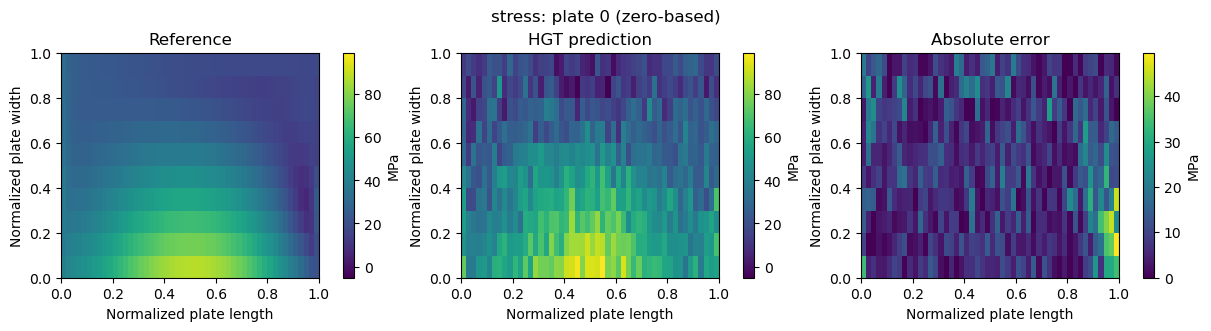

In [4]:
test_index = 0
plate_index = 0
sample = splits['test'][test_index]
sample_metrics, sample_true, sample_predicted = evaluate(model, [sample], device)
print('Original sample ID:', sample.sample_id)
print('Graph RMSE:', sample_metrics['rmse'], 'MPa')
fig = plot_prediction(sample_true, sample_predicted, plate=plate_index)
display(fig)
plt.close(fig)

## Compare field values and a representative path

The scatter uses every field value in the selected test graph. The path follows the middle row of the selected plate. These plots show both the learned spatial response and the errors that remain with very limited training data.

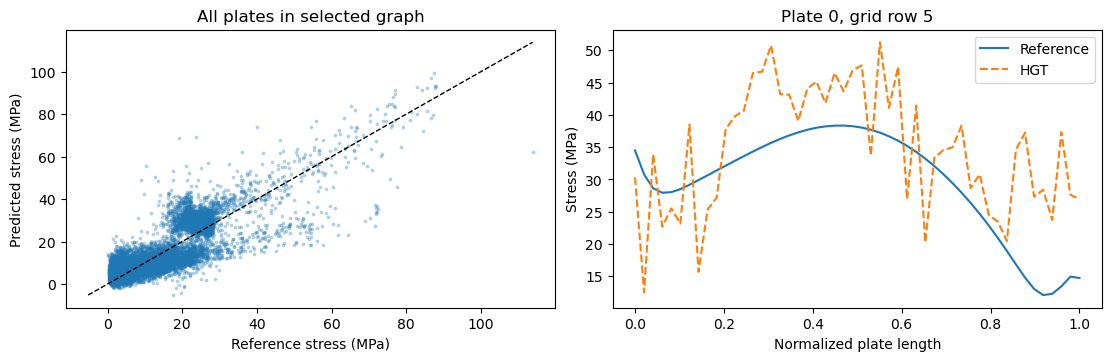

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].scatter(sample_true.ravel(), sample_predicted.ravel(), s=3, alpha=0.25)
lim = [min(sample_true.min(), sample_predicted.min()), max(sample_true.max(), sample_predicted.max())]
axes[0].plot(lim, lim, 'k--', linewidth=1)
axes[0].set(xlabel='Reference stress (MPa)', ylabel='Predicted stress (MPa)', title='All plates in selected graph')
truth_grid = sample_true[plate_index].reshape(10, 50, order='F')
pred_grid = sample_predicted[plate_index].reshape(10, 50, order='F')
x = np.linspace(0, 1, 50)
axes[1].plot(x, truth_grid[5], label='Reference')
axes[1].plot(x, pred_grid[5], '--', label='HGT')
axes[1].set(xlabel='Normalized plate length', ylabel='Stress (MPa)', title=f'Plate {plate_index}, grid row 5')
axes[1].legend()
display(fig)
plt.close(fig)

## Training history of the supplied checkpoint

Checkpoint selection uses validation MSE; the test set is used only for evaluation. The full 200-epoch history is included so the pretrained example is inspectable.

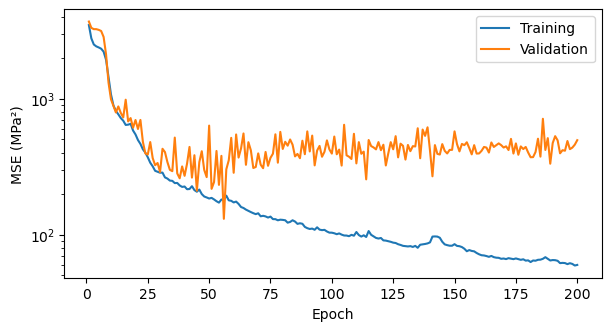

In [6]:
history = json.loads((ROOT / 'pretrained/training_history.json').read_text())
fig, ax = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
for key, label in [('train_mse', 'Training'), ('val_mse', 'Validation')]:
    ax.semilogy([h['epoch'] for h in history], [h[key] for h in history], label=label)
ax.set(xlabel='Epoch', ylabel='MSE (MPa²)')
ax.legend()
display(fig)
plt.close(fig)

## Optional: train from scratch

The following **three-epoch** run verifies optimization, validation, and checkpoint saving. It does not overwrite the bundled model, and it is too short to establish prediction accuracy. Set `RUN_TRAINING=False` to skip it. To reproduce the supplied training recipe, use 200 epochs (or the command in `README.md`). GPU timings and exact floating-point results can vary.

`target` can also be `U1`, `U2`, or `U3`; displacement targets retain their stored research scaling.

In [7]:
RUN_TRAINING = True
if RUN_TRAINING:
    fresh_model, quick_history = train(splits, ROOT / 'outputs/notebook_training', device=device, epochs=3)
    reloaded, saved = load_checkpoint(ROOT / 'outputs/notebook_training/best_model.pt', graph, device)
    with torch.no_grad():
        fresh_model.eval()
        reloaded.eval()
        check = sample.clone().to(device)
        a = fresh_model(check.x_dict, check.edge_index_dict)['plate']
        b = reloaded(check.x_dict, check.edge_index_dict)['plate']
        torch.testing.assert_close(a, b)
    print('Saved checkpoint reproduces the trained model predictions.')

Epoch 1/3: train MSE=2311.9534, val MSE=3842.8270


Epoch 2/3: train MSE=2055.1356, val MSE=3653.0336


Epoch 3/3: train MSE=1860.9431, val MSE=3503.3882


Saved checkpoint reproduces the trained model predictions.


## Scope

This release is a compact graph-construction, training, and inference example. It omits the full database, ablation variants, and other cases. The test errors above belong to this small release and do not reproduce the paper's full benchmark results. See `data/README.md` for sample provenance, scaling, and the corrected relation orientation.